## 1. Imports

In [1]:
import os
import sys
import pickle
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.pyplot as plt
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

## 2. Paths & Configuration

In [2]:
# ── Absolute paths ──────────────────────────────────────────────────────────────
SCTRANSLATOR_REPO = r'C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator'
CHECKPOINT_DIR    = r'C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff'

# In a notebook __file__ is not defined, so we use the current working directory.
# Make sure the notebook is located in the same folder as the .joblib data files.
SCRIPT_DIR = os.path.dirname(os.path.abspath('__file__'))  # notebook directory

# Add scTranslator code to path
sys.path.append(os.path.join(SCTRANSLATOR_REPO, 'code', 'model'))
from performer_enc_dec import scPerformerEncDec

print(f"SCRIPT_DIR:        {SCRIPT_DIR}")
print(f"SCTRANSLATOR_REPO: {SCTRANSLATOR_REPO}")
print(f"CHECKPOINT_DIR:    {CHECKPOINT_DIR}")

SCRIPT_DIR:        c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\tmt
SCTRANSLATOR_REPO: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator
CHECKPOINT_DIR:    C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff


In [3]:
CONFIG = {
    'rna_path':  os.path.join(SCRIPT_DIR, 'TMT_transcriptomics.joblib'),
    'prot_path': os.path.join(SCRIPT_DIR, 'TMT_proteomics.joblib'),
    'dic_path':  os.path.join(SCTRANSLATOR_REPO, 'code', 'model', 'ID_dic'),
    'checkpoints': {
        '2M':   os.path.join(CHECKPOINT_DIR, 'scTranslator_2M.pt'),
        '10K':  os.path.join(CHECKPOINT_DIR, 'scTranslator_10K.pt'),
        '160K': os.path.join(CHECKPOINT_DIR, 'scTranslator_160K.pt'),
    },
    'enc_max_seq_len': 20000,
    'dec_max_seq_len': 1000,   # Decoder limit
    'batch_size': 8,          
    'output_dir': os.path.join(SCRIPT_DIR, 'benchmark_results_tmt'),
}

# Quick sanity check – print which checkpoint files exist
for name, path in CONFIG['checkpoints'].items():
    status = 'FOUND' if os.path.exists(path) else 'MISSING'
    print(f"  [{status}] {name}: {path}")

  [FOUND] 2M: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_2M.pt
  [FOUND] 10K: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt
  [FOUND] 160K: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_160K.pt


## 3. ID Mapping Helpers

In [4]:
def load_id_dictionaries(dic_path):
    """Load scTranslator ID mapping dictionaries."""
    with open(os.path.join(dic_path, 'hgs_to_EntrezID.pkl'), 'rb') as f:
        hgs_to_entrez = pickle.load(f)
    with open(os.path.join(dic_path, 'EntrezID_to_myID.pkl'), 'rb') as f:
        entrez_to_myid = pickle.load(f)
    return hgs_to_entrez, entrez_to_myid


def gene_symbol_to_myid(gene_symbol, hgs_to_entrez, entrez_to_myid):
    """Convert gene symbol to scTranslator ID."""
    entrez_id = hgs_to_entrez.get(gene_symbol)
    if entrez_id:
        my_id = entrez_to_myid.get(entrez_id)
        return int(my_id) if my_id else None
    return None


def map_genes_to_ids(gene_list, hgs_to_entrez, entrez_to_myid):
    """Map a list of gene symbols to scTranslator IDs."""
    mapped = []
    unmapped = []
    for gene in gene_list:
        my_id = gene_symbol_to_myid(gene, hgs_to_entrez, entrez_to_myid)
        if my_id is not None:
            mapped.append((gene, my_id))
        else:
            unmapped.append(gene)
    return mapped, unmapped

## 4. Normalization

In [5]:
def cellwise_minmax(X, low=1e-8, high=1.0):
    """
    Paper's normalization: per-cell min-max scaling.
    Maps each cell's values to [low, high] range.
    """
    X = X.astype(np.float32)
    mins = X.min(axis=1, keepdims=True)
    maxs = X.max(axis=1, keepdims=True)
    denom = (maxs - mins)
    denom[denom == 0] = 1.0  # Avoid division by zero
    Xn = (X - mins) / denom
    Xn = Xn * (high - low) + low
    return Xn.astype(np.float32)

## 5. Data Preparation (NaN Handling + ID Mapping)

**NaN strategy (threshold-based):**
- Columns where **>50 %** of values across samples are NaN are **dropped**.
- Remaining NaN values are **filled with `1e-8`** (a small non-zero value; 0 is the special prediction token for scTranslator's decoder).

In [6]:
def prepare_data(config):
    """
    Load and prepare RNA and protein data with ID mapping.

    NaN handling (threshold-based):
    - Columns (genes / proteins) where >50% of values across samples are NaN
      are dropped entirely.
    - Remaining NaN values are filled with 1e-8 (a small non-zero value,
      since 0 is the special prediction token for scTranslator's decoder).
    """
    NAN_THRESHOLD = 0.50  # drop column if more than 50% of samples are NaN

    print("Loading data...")
    rna_df = joblib.load(config['rna_path'])
    prot_df = joblib.load(config['prot_path'])

    rna_orig_cols  = len(rna_df.columns)
    prot_orig_cols = len(prot_df.columns)
    n_samples_rna  = len(rna_df)
    n_samples_prot = len(prot_df)

    print(f"RNA shape (raw):     {rna_df.shape}")
    print(f"Protein shape (raw): {prot_df.shape}")

    # ── NaN handling: drop if >50% NaN, else fill with 1e-8 ─────────────
    rna_nan_frac  = rna_df.isna().sum() / n_samples_rna
    prot_nan_frac = prot_df.isna().sum() / n_samples_prot

    rna_drop_cols  = rna_nan_frac[rna_nan_frac > NAN_THRESHOLD].index.tolist()
    prot_drop_cols = prot_nan_frac[prot_nan_frac > NAN_THRESHOLD].index.tolist()

    rna_fill_cols  = rna_nan_frac[(rna_nan_frac > 0) & (rna_nan_frac <= NAN_THRESHOLD)].index.tolist()
    prot_fill_cols = prot_nan_frac[(prot_nan_frac > 0) & (prot_nan_frac <= NAN_THRESHOLD)].index.tolist()

    # Drop columns exceeding the NaN threshold
    rna_df  = rna_df.drop(columns=rna_drop_cols)
    prot_df = prot_df.drop(columns=prot_drop_cols)

    # Fill remaining NaN values with 1e-8 (not 0, which is reserved)
    rna_df  = rna_df.fillna(1e-8)
    prot_df = prot_df.fillna(1e-8)

    print(f"\nNaN handling (threshold: >{NAN_THRESHOLD*100:.0f}% NaN -> drop, else fill with 1e-8):")
    print(f"  RNA genes dropped  (>{NAN_THRESHOLD*100:.0f}% NaN): {len(rna_drop_cols):,} / {rna_orig_cols} "
          f"({100*len(rna_drop_cols)/rna_orig_cols:.1f}%)")
    print(f"  RNA genes filled   (<=50% NaN):  {len(rna_fill_cols):,} / {rna_orig_cols} "
          f"({100*len(rna_fill_cols)/rna_orig_cols:.1f}%)")
    print(f"  Proteins dropped   (>{NAN_THRESHOLD*100:.0f}% NaN): {len(prot_drop_cols):,} / {prot_orig_cols} "
          f"({100*len(prot_drop_cols)/prot_orig_cols:.1f}%)")
    print(f"  Proteins filled    (<=50% NaN):  {len(prot_fill_cols):,} / {prot_orig_cols} "
          f"({100*len(prot_fill_cols)/prot_orig_cols:.1f}%)")
    print(f"  RNA shape after:     {rna_df.shape}")
    print(f"  Protein shape after: {prot_df.shape}")

    # ── ID mapping ──────────────────────────────────────────────────────
    hgs_to_entrez, entrez_to_myid = load_id_dictionaries(config['dic_path'])

    # Map RNA genes
    print("\nMapping RNA genes to scTranslator IDs...")
    rna_mapped, rna_unmapped = map_genes_to_ids(
        rna_df.columns.tolist(), hgs_to_entrez, entrez_to_myid
    )
    print(f"  RNA genes after NaN removal: {len(rna_df.columns)}")
    print(f"  Mapped to scTranslator:      {len(rna_mapped)} ({100*len(rna_mapped)/len(rna_df.columns):.1f}%)")
    print(f"  Unmapped (thrown out):        {len(rna_unmapped)} ({100*len(rna_unmapped)/len(rna_df.columns):.1f}%)")
    if rna_unmapped:
        print(f"  First 20 unmapped genes:     {rna_unmapped[:20]}")

    # Map protein genes
    print("\nMapping proteins to scTranslator IDs...")
    prot_mapped, prot_unmapped = map_genes_to_ids(
        prot_df.columns.tolist(), hgs_to_entrez, entrez_to_myid
    )
    print(f"  Proteins after NaN removal:  {len(prot_df.columns)}")
    print(f"  Mapped to scTranslator:      {len(prot_mapped)} ({100*len(prot_mapped)/len(prot_df.columns):.1f}%)")
    print(f"  Unmapped (thrown out):        {len(prot_unmapped)} ({100*len(prot_unmapped)/len(prot_df.columns):.1f}%)")
    if prot_unmapped:
        print(f"  Unmapped proteins:           {prot_unmapped}")

    # ── Summary of total attrition ──────────────────────────────────────
    print(f"\n  === Total gene / protein attrition ===")
    print(f"  RNA:  {rna_orig_cols} -> {len(rna_mapped)}  "
          f"(dropped {len(rna_drop_cols)} NaN + {len(rna_unmapped)} unmapped "
          f"= {rna_orig_cols - len(rna_mapped)} total removed, "
          f"{len(rna_fill_cols)} cols NaN-filled)")
    print(f"  Prot: {prot_orig_cols} -> {len(prot_mapped)}  "
          f"(dropped {len(prot_drop_cols)} NaN + {len(prot_unmapped)} unmapped "
          f"= {prot_orig_cols - len(prot_mapped)} total removed, "
          f"{len(prot_fill_cols)} cols NaN-filled)")

    # Extract mapped data
    rna_genes  = [g for g, _ in rna_mapped]
    rna_ids    = [i for _, i in rna_mapped]
    prot_genes = [g for g, _ in prot_mapped]
    prot_ids   = [i for _, i in prot_mapped]

    # Filter dataframes to mapped genes only
    rna_values  = rna_df[rna_genes].values
    prot_values = prot_df[prot_genes].values

    # Normalize using paper's method
    print("\nApplying cell-wise min-max normalization...")
    rna_norm  = cellwise_minmax(rna_values)
    prot_norm = cellwise_minmax(prot_values)

    return {
        'rna_values':  rna_norm,
        'rna_ids':     np.array(rna_ids),
        'rna_genes':   rna_genes,
        'prot_values': prot_norm,
        'prot_ids':    np.array(prot_ids),
        'prot_genes':  prot_genes,
        'cell_names':  rna_df.index.tolist(),
        'n_cells':     rna_df.shape[0],
        'n_rna_genes': len(rna_genes),
        'n_proteins':  len(prot_genes),
        # keep mapping stats for the summary file
        'mapping_stats': {
            'rna_total':           rna_orig_cols,
            'rna_dropped_nan':     len(rna_drop_cols),
            'rna_filled_nan':      len(rna_fill_cols),
            'rna_after_nan':       len(rna_df.columns),
            'rna_mapped':          len(rna_mapped),
            'rna_unmapped':        len(rna_unmapped),
            'prot_total':          prot_orig_cols,
            'prot_dropped_nan':    len(prot_drop_cols),
            'prot_filled_nan':     len(prot_fill_cols),
            'prot_after_nan':      len(prot_df.columns),
            'prot_mapped':         len(prot_mapped),
            'prot_unmapped':       len(prot_unmapped),
            'prot_unmapped_names': prot_unmapped,
            'nan_threshold':       NAN_THRESHOLD,
        },
    }

## 6. Model Inference

In [7]:
def prepare_batch(rna_values, rna_ids, prot_ids, enc_max_len, dec_max_len, device):
    """
    Prepare a batch for model inference.
    Handles padding/truncation for encoder and decoder sequences.
    """
    batch_size = rna_values.shape[0]
    n_rna  = rna_values.shape[1]
    n_prot = len(prot_ids)

    # Encoder (RNA) – truncate or pad to enc_max_len
    if n_rna >= enc_max_len:
        rna_val  = rna_values[:, :enc_max_len]
        rna_id   = np.tile(rna_ids[:enc_max_len], (batch_size, 1))
        rna_mask = np.ones((batch_size, enc_max_len), dtype=bool)
    else:
        rna_val = np.zeros((batch_size, enc_max_len), dtype=np.float32)
        rna_val[:, :n_rna] = rna_values
        rna_id = np.zeros((batch_size, enc_max_len), dtype=np.int64)
        rna_id[:, :n_rna] = rna_ids
        rna_mask = np.zeros((batch_size, enc_max_len), dtype=bool)
        rna_mask[:, :n_rna] = True

    # Decoder (Protein) – pad to dec_max_len (should be <= 1000)
    prot_val  = np.zeros((batch_size, dec_max_len), dtype=np.float32)
    prot_id   = np.zeros((batch_size, dec_max_len), dtype=np.int64)
    prot_mask = np.zeros((batch_size, dec_max_len), dtype=bool)

    prot_id[:, :n_prot]   = prot_ids
    prot_mask[:, :n_prot] = True

    # Convert to tensors
    rna_val_t  = torch.tensor(rna_val,  dtype=torch.float32).to(device)
    rna_id_t   = torch.tensor(rna_id,   dtype=torch.long).to(device)
    rna_mask_t = torch.tensor(rna_mask,  dtype=torch.bool).to(device)
    prot_id_t  = torch.tensor(prot_id,  dtype=torch.long).to(device)
    prot_mask_t = torch.tensor(prot_mask, dtype=torch.bool).to(device)

    return rna_val_t, rna_id_t, rna_mask_t, prot_id_t, prot_mask_t, n_prot


def run_inference(model, data, config, device):
    """
    Run inference on all cells, chunking proteins as needed.
    Decoder max is 1000, so we chunk and concatenate results.
    """
    model.eval()

    n_cells    = data['n_cells']
    n_proteins = data['n_proteins']
    dec_max    = config['dec_max_seq_len']
    batch_size = config['batch_size']

    # Calculate protein chunks
    n_chunks = int(np.ceil(n_proteins / dec_max))
    print(f"\nProtein chunking: {n_proteins} proteins -> {n_chunks} chunks of <={dec_max}")

    # Storage for all predictions
    all_predictions = np.zeros((n_cells, n_proteins), dtype=np.float32)

    # Process each protein chunk
    for chunk_idx in range(n_chunks):
        start_prot = chunk_idx * dec_max
        end_prot   = min((chunk_idx + 1) * dec_max, n_proteins)
        chunk_prot_ids = data['prot_ids'][start_prot:end_prot]
        chunk_size = end_prot - start_prot

        print(f"  Chunk {chunk_idx+1}/{n_chunks}: proteins {start_prot}-{end_prot} ({chunk_size} proteins)")

        chunk_predictions = []

        # Process in batches
        for batch_start in tqdm(range(0, n_cells, batch_size), desc=f"  Chunk {chunk_idx+1}"):
            batch_end = min(batch_start + batch_size, n_cells)
            batch_rna = data['rna_values'][batch_start:batch_end]

            # Prepare batch
            rna_val, rna_id, rna_mask, prot_id, prot_mask, n_prot = prepare_batch(
                batch_rna, data['rna_ids'], chunk_prot_ids,
                config['enc_max_seq_len'], dec_max, device
            )

            # Forward pass
            with torch.no_grad():
                _, y_hat = model(rna_val, rna_id, prot_id,
                                 enc_mask=rna_mask, dec_mask=prot_mask)
                y_hat = torch.squeeze(y_hat)

                # Handle single sample case
                if len(y_hat.shape) == 1:
                    y_hat = y_hat.unsqueeze(0)

                # Extract only the valid protein predictions (not padding)
                y_hat_valid = y_hat[:, :chunk_size].cpu().numpy()
                chunk_predictions.append(y_hat_valid)

        # Concatenate batch predictions for this chunk
        chunk_predictions = np.vstack(chunk_predictions)
        all_predictions[:, start_prot:end_prot] = chunk_predictions

    return all_predictions

## 7. Metrics

In [8]:
def compute_metrics(y_true, y_pred):
    """
    Per-cell (sample-wise) metrics, then averaged:
    cosine similarity, PCC, MSE, MAE.
    """
    n_cells = y_true.shape[0]

    cosines, pccs, mses, maes = [], [], [], []

    for i in range(n_cells):
        true_i = y_true[i]
        pred_i = y_pred[i]

        # Cosine similarity
        norm_true = np.linalg.norm(true_i)
        norm_pred = np.linalg.norm(pred_i)
        cos = np.dot(true_i, pred_i) / (norm_true * norm_pred) if (norm_true > 0 and norm_pred > 0) else 0.0
        cosines.append(cos)

        # Pearson correlation
        pcc = pearsonr(true_i, pred_i)[0] if (np.std(true_i) > 0 and np.std(pred_i) > 0) else 0.0
        pccs.append(pcc)

        # MSE / MAE
        mses.append(mean_squared_error(true_i, pred_i))
        maes.append(mean_absolute_error(true_i, pred_i))

    return {
        'cosine': np.array(cosines),
        'pcc':    np.array(pccs),
        'mse':    np.array(mses),
        'mae':    np.array(maes),
    }


def compute_protein_wise_metrics(y_true, y_pred):
    """Compute PCC per protein (across all cells)."""
    n_proteins = y_true.shape[1]
    pccs = []
    for j in range(n_proteins):
        true_j = y_true[:, j]
        pred_j = y_pred[:, j]
        pcc = pearsonr(true_j, pred_j)[0] if (np.std(true_j) > 0 and np.std(pred_j) > 0) else 0.0
        pccs.append(pcc)
    return np.array(pccs)

## 8. Visualization

In [9]:
def plot_results(metrics, protein_pccs, prot_genes, checkpoint_name, output_dir):
    """Generate visualization plots."""
    os.makedirs(output_dir, exist_ok=True)

    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    fig.suptitle(f'scTranslator TMT Benchmark – {checkpoint_name}', fontsize=14)

    # 1. Cosine similarity histogram
    ax = axes[0, 0]
    ax.hist(metrics['cosine'], bins=30, edgecolor='black', alpha=0.7)
    ax.axvline(metrics['cosine'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["cosine"].mean():.3f}')
    ax.set_xlabel('Cosine Similarity')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell Cosine Similarity')
    ax.legend()

    # 2. PCC histogram
    ax = axes[0, 1]
    ax.hist(metrics['pcc'], bins=30, edgecolor='black', alpha=0.7, color='orange')
    ax.axvline(metrics['pcc'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["pcc"].mean():.3f}')
    ax.set_xlabel('Pearson Correlation')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell PCC')
    ax.legend()

    # 3. MSE histogram
    ax = axes[0, 2]
    ax.hist(metrics['mse'], bins=30, edgecolor='black', alpha=0.7, color='green')
    ax.axvline(metrics['mse'].mean(), color='red', linestyle='--',
               label=f'Mean: {metrics["mse"].mean():.4f}')
    ax.set_xlabel('MSE')
    ax.set_ylabel('Count')
    ax.set_title('Per-Cell MSE')
    ax.legend()

    # 4. Protein-wise PCC histogram
    ax = axes[1, 0]
    ax.hist(protein_pccs, bins=50, edgecolor='black', alpha=0.7, color='purple')
    ax.axvline(protein_pccs.mean(), color='red', linestyle='--',
               label=f'Mean: {protein_pccs.mean():.3f}')
    ax.set_xlabel('Pearson Correlation')
    ax.set_ylabel('Count')
    ax.set_title('Per-Protein PCC (across cells)')
    ax.legend()

    # 5. Top/Bottom proteins by PCC
    ax = axes[1, 1]
    sorted_idx = np.argsort(protein_pccs)[::-1]
    top_10    = sorted_idx[:10]
    bottom_10 = sorted_idx[-10:]

    proteins_to_show = list(top_10) + list(bottom_10)
    labels = [prot_genes[i] for i in proteins_to_show]
    values = [protein_pccs[i] for i in proteins_to_show]
    colors = ['green'] * 10 + ['red'] * 10

    ax.barh(range(20), values, color=colors, alpha=0.7)
    ax.set_yticks(range(20))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('PCC')
    ax.set_title('Top 10 / Bottom 10 Proteins by PCC')
    ax.axvline(0, color='black', linestyle='-', linewidth=0.5)

    # 6. Summary statistics
    ax = axes[1, 2]
    ax.axis('off')
    summary_text = f"""
    Summary Statistics ({checkpoint_name})
    =====================================

    Per-Cell Metrics (n={len(metrics['cosine'])} cells):

    Cosine Similarity:
      Mean: {metrics['cosine'].mean():.4f} +/- {metrics['cosine'].std():.4f}
      Min:  {metrics['cosine'].min():.4f}
      Max:  {metrics['cosine'].max():.4f}

    Pearson Correlation:
      Mean: {metrics['pcc'].mean():.4f} +/- {metrics['pcc'].std():.4f}
      Min:  {metrics['pcc'].min():.4f}
      Max:  {metrics['pcc'].max():.4f}

    MSE:
      Mean: {metrics['mse'].mean():.6f} +/- {metrics['mse'].std():.6f}

    MAE:
      Mean: {metrics['mae'].mean():.6f} +/- {metrics['mae'].std():.6f}

    Per-Protein PCC (n={len(protein_pccs)} proteins):
      Mean: {protein_pccs.mean():.4f} +/- {protein_pccs.std():.4f}
      Positive: {(protein_pccs > 0).sum()} ({100*(protein_pccs > 0).mean():.1f}%)
      > 0.3:    {(protein_pccs > 0.3).sum()} ({100*(protein_pccs > 0.3).mean():.1f}%)
      > 0.5:    {(protein_pccs > 0.5).sum()} ({100*(protein_pccs > 0.5).mean():.1f}%)
    """
    ax.text(0.1, 0.9, summary_text, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', fontfamily='monospace')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'benchmark_{checkpoint_name}.png'), dpi=150)
    plt.show()
    print(f"  Saved plot: benchmark_{checkpoint_name}.png")


def plot_scatter_examples(y_true, y_pred, prot_genes, checkpoint_name, output_dir):
    """Plot scatter plots for selected proteins."""
    protein_pccs = compute_protein_wise_metrics(y_true, y_pred)
    sorted_idx   = np.argsort(protein_pccs)[::-1]

    n = len(sorted_idx)
    indices = [
        sorted_idx[0],        # Best
        sorted_idx[n // 4],   # 75th percentile
        sorted_idx[n // 2],   # Median
        sorted_idx[3*n // 4], # 25th percentile
        sorted_idx[-1],       # Worst
    ]

    fig, axes = plt.subplots(1, 5, figsize=(20, 4))
    fig.suptitle(f'True vs Predicted Protein Abundance – {checkpoint_name}', fontsize=12)

    for ax, idx in zip(axes, indices):
        true_vals = y_true[:, idx]
        pred_vals = y_pred[:, idx]
        pcc = protein_pccs[idx]

        ax.scatter(true_vals, pred_vals, alpha=0.5, s=10)
        ax.plot([true_vals.min(), true_vals.max()],
                [true_vals.min(), true_vals.max()],
                'r--', linewidth=1)
        ax.set_xlabel('True')
        ax.set_ylabel('Predicted')
        ax.set_title(f'{prot_genes[idx]}\nPCC={pcc:.3f}')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f'scatter_{checkpoint_name}.png'), dpi=150)
    plt.show()
    print(f"  Saved plot: scatter_{checkpoint_name}.png")

## 9. Benchmark Runner (single checkpoint)

In [10]:
def benchmark_checkpoint(checkpoint_name, checkpoint_path, data, config, device):
    """Run benchmark for a single checkpoint."""
    print(f"\n{'='*60}")
    print(f"Benchmarking: {checkpoint_name}")
    print(f"Checkpoint: {checkpoint_path}")
    print(f"{'='*60}")

    # Load model
    print("\nLoading model...")
    model = torch.load(checkpoint_path, map_location=device)
    model.eval()
    print(f"  Model loaded on {device}")

    # Run inference
    print("\nRunning inference...")
    predictions = run_inference(model, data, config, device)

    # Dynamic dimension validation (no hardcoded counts)
    expected_cells    = data['n_cells']
    expected_proteins = data['n_proteins']
    if predictions.shape != (expected_cells, expected_proteins):
        raise ValueError(
            f"Shape mismatch: got {predictions.shape}, "
            f"expected ({expected_cells}, {expected_proteins})"
        )

    # Save raw predictions
    os.makedirs(config['output_dir'], exist_ok=True)
    pred_path = os.path.join(config['output_dir'], f'predictions_{checkpoint_name}.npy')
    np.save(pred_path, predictions)
    np.save(os.path.join(config['output_dir'], f'protein_names_{checkpoint_name}.npy'),
            np.array(data['prot_genes']))
    np.save(os.path.join(config['output_dir'], f'protein_ids_{checkpoint_name}.npy'),
            np.array(data['prot_ids']))
    np.save(os.path.join(config['output_dir'], f'cell_names_{checkpoint_name}.npy'),
            np.array(data['cell_names']))
    np.savez(
        os.path.join(config['output_dir'], f'predictions_{checkpoint_name}.npz'),
        predictions=predictions,
        protein_names=np.array(data['prot_genes']),
        protein_ids=np.array(data['prot_ids']),
        cell_names=np.array(data['cell_names']),
    )
    print(f"  Saved predictions: {pred_path}")

    # Compute metrics
    print("\nComputing metrics...")
    metrics      = compute_metrics(data['prot_values'], predictions)
    protein_pccs = compute_protein_wise_metrics(data['prot_values'], predictions)

    # Print summary
    print(f"\n--- Results for {checkpoint_name} ---")
    print(f"Per-Cell Cosine: {metrics['cosine'].mean():.4f} +/- {metrics['cosine'].std():.4f}")
    print(f"Per-Cell PCC:    {metrics['pcc'].mean():.4f} +/- {metrics['pcc'].std():.4f}")
    print(f"Per-Cell MSE:    {metrics['mse'].mean():.6f} +/- {metrics['mse'].std():.6f}")
    print(f"Per-Cell MAE:    {metrics['mae'].mean():.6f} +/- {metrics['mae'].std():.6f}")
    print(f"Per-Protein PCC: {protein_pccs.mean():.4f} +/- {protein_pccs.std():.4f}")

    # Generate plots
    print("\nGenerating visualizations...")
    plot_results(metrics, protein_pccs, data['prot_genes'],
                 checkpoint_name, config['output_dir'])
    plot_scatter_examples(data['prot_values'], predictions, data['prot_genes'],
                          checkpoint_name, config['output_dir'])

    # Save detailed results
    results = {
        'checkpoint':   checkpoint_name,
        'metrics':      metrics,
        'protein_pccs': protein_pccs,
        'predictions':  predictions,
        'prot_genes':   data['prot_genes'],
        'cell_names':   data['cell_names'],
    }
    return results

---
## 10. Run the Pipeline

Everything below actually **executes** the benchmark.  
The cells above only defined functions and configuration.

### 10.1 Device Setup

In [11]:
print("=" * 60)
print("scTranslator Benchmarking Pipeline – TMT Dataset")
print("=" * 60)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"\nDevice: {device}")
if device == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

os.makedirs(CONFIG['output_dir'], exist_ok=True)

scTranslator Benchmarking Pipeline – TMT Dataset

Device: cuda
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
GPU Memory: 17.2 GB


### 10.2 Prepare Data

In [12]:
data = prepare_data(CONFIG)

Loading data...
RNA shape (raw):     (1924, 15001)
Protein shape (raw): (1924, 6885)

NaN handling (threshold: >50% NaN -> drop, else fill with 1e-8):
  RNA genes dropped  (>50% NaN): 0 / 15001 (0.0%)
  RNA genes filled   (<=50% NaN):  7,844 / 15001 (52.3%)
  Proteins dropped   (>50% NaN): 0 / 6885 (0.0%)
  Proteins filled    (<=50% NaN):  5,000 / 6885 (72.6%)
  RNA shape after:     (1924, 15001)
  Protein shape after: (1924, 6885)

Mapping RNA genes to scTranslator IDs...
  RNA genes after NaN removal: 15001
  Mapped to scTranslator:      14522 (96.8%)
  Unmapped (thrown out):        479 (3.2%)
  First 20 unmapped genes:     ['ABC12-49244600F4.3', 'ABC7-42389800N19.1', 'AC002055.4', 'AC002472.9', 'AC003682.1', 'AC004381.6', 'AC004410.1', 'AC004696.1', 'AC004706.1', 'AC004985.13', 'AC005013.1', 'AC005280.1', 'AC005726.6', 'AC006276.1', 'AC006465.3', 'AC007390.5', 'AC007405.7', 'AC008073.5', 'AC008073.6', 'AC010336.1']

Mapping proteins to scTranslator IDs...
  Proteins after NaN remova

### 10.3 Run Benchmarks (all checkpoints)


Benchmarking: 2M
Checkpoint: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_2M.pt

Loading model...
  Model loaded on cuda

Running inference...

Protein chunking: 6853 proteins -> 7 chunks of <=1000
  Chunk 1/7: proteins 0-1000 (1000 proteins)


  Chunk 1: 100%|██████████| 241/241 [08:24<00:00,  2.09s/it]


  Chunk 2/7: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 241/241 [08:46<00:00,  2.19s/it]


  Chunk 3/7: proteins 2000-3000 (1000 proteins)


  Chunk 3: 100%|██████████| 241/241 [21:43<00:00,  5.41s/it]


... (5 outputs left out)

  Chunk 6: 100%|██████████| 241/241 [01:17<00:00,  3.09it/s]


  Chunk 7/7: proteins 6000-6853 (853 proteins)


  Chunk 7: 100%|██████████| 241/241 [10:46<00:00,  2.68s/it]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\tmt\benchmark_results_tmt\predictions_2M.npy

Computing metrics...

--- Results for 2M ---
Per-Cell Cosine: 0.0204 +/- 0.0027
Per-Cell PCC:    0.0035 +/- 0.0091
Per-Cell MSE:    75772.253742 +/- 19005.100464
Per-Cell MAE:    199.685356 +/- 25.666507
Per-Protein PCC: 0.0562 +/- 0.4037

Generating visualizations...


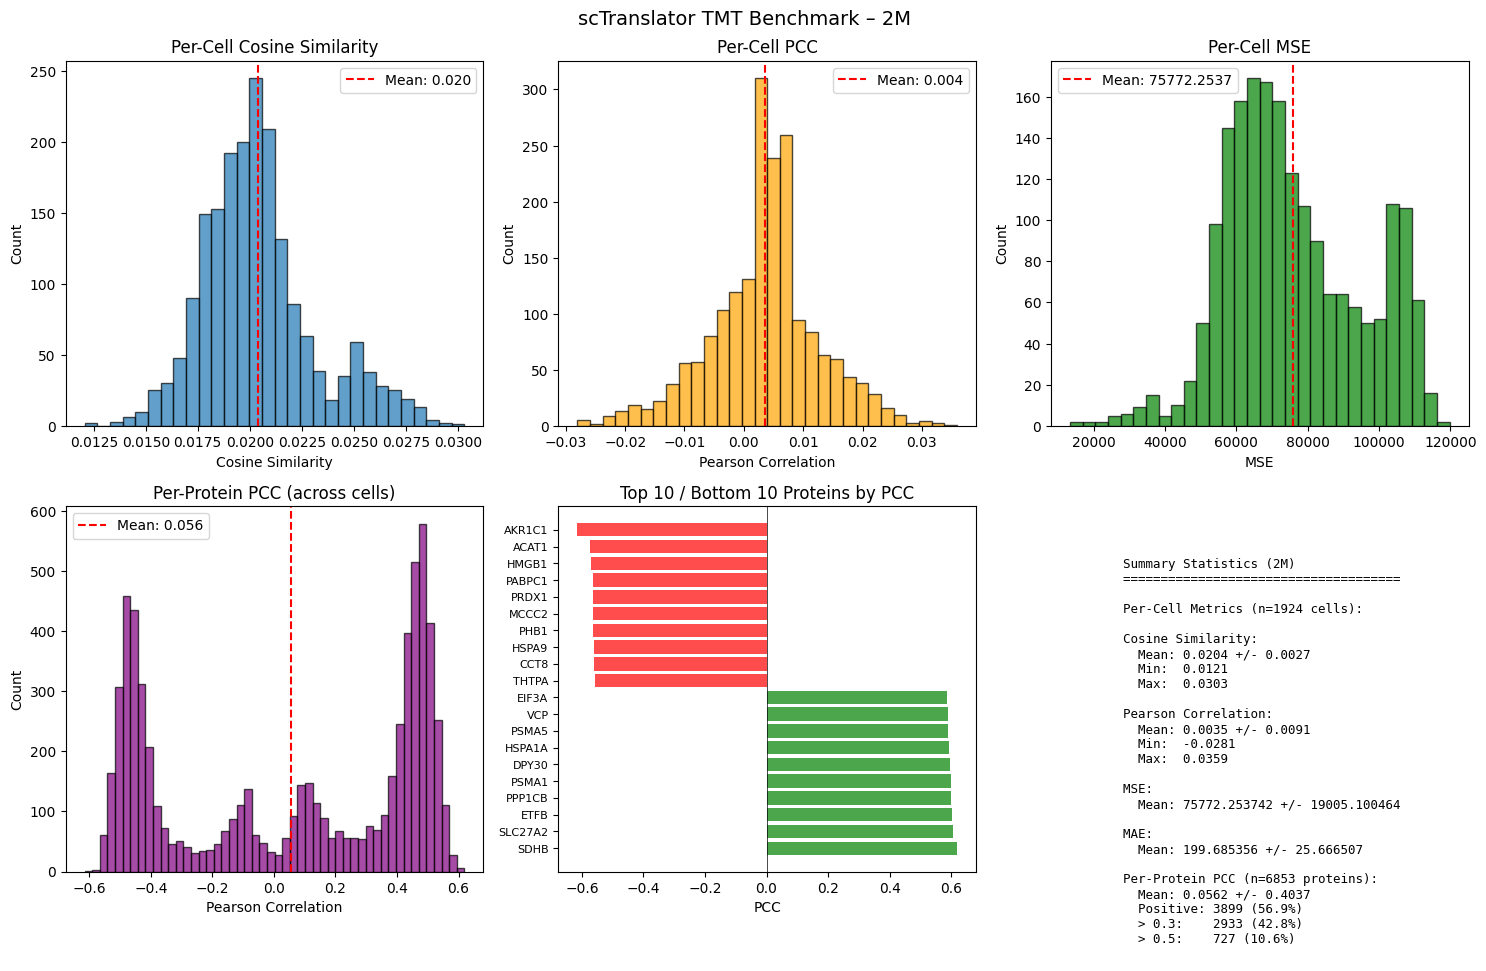

  Saved plot: benchmark_2M.png


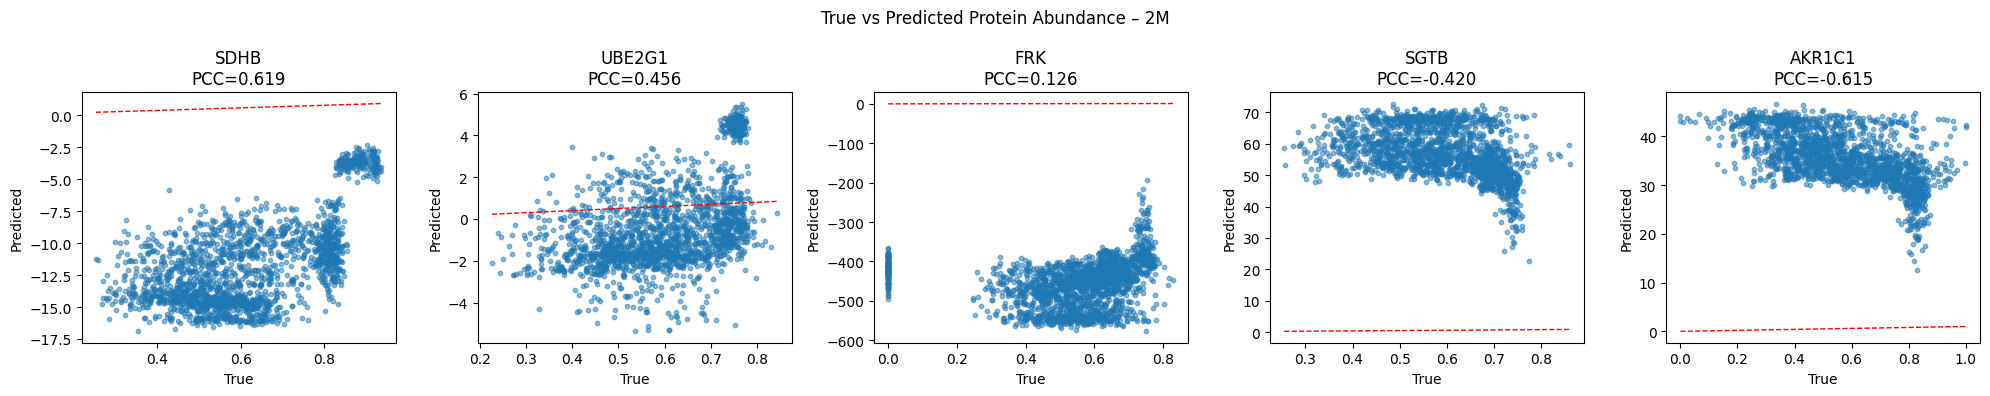

  Saved plot: scatter_2M.png

Benchmarking: 10K
Checkpoint: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_10K.pt

Loading model...
  Model loaded on cuda

Running inference...

Protein chunking: 6853 proteins -> 7 chunks of <=1000
  Chunk 1/7: proteins 0-1000 (1000 proteins)


  Chunk 1: 100%|██████████| 241/241 [01:10<00:00,  3.43it/s]


  Chunk 2/7: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 241/241 [00:55<00:00,  4.31it/s]


  Chunk 3/7: proteins 2000-3000 (1000 proteins)


  Chunk 3: 100%|██████████| 241/241 [00:57<00:00,  4.19it/s]


... (5 outputs left out)

  Chunk 6: 100%|██████████| 241/241 [00:57<00:00,  4.21it/s]


  Chunk 7/7: proteins 6000-6853 (853 proteins)


  Chunk 7: 100%|██████████| 241/241 [00:56<00:00,  4.23it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\tmt\benchmark_results_tmt\predictions_10K.npy

Computing metrics...

--- Results for 10K ---
Per-Cell Cosine: 0.9635 +/- 0.0198
Per-Cell PCC:    0.0649 +/- 0.1050
Per-Cell MSE:    0.040985 +/- 0.029458
Per-Cell MAE:    0.161153 +/- 0.067997
Per-Protein PCC: -0.2595 +/- 0.2683

Generating visualizations...


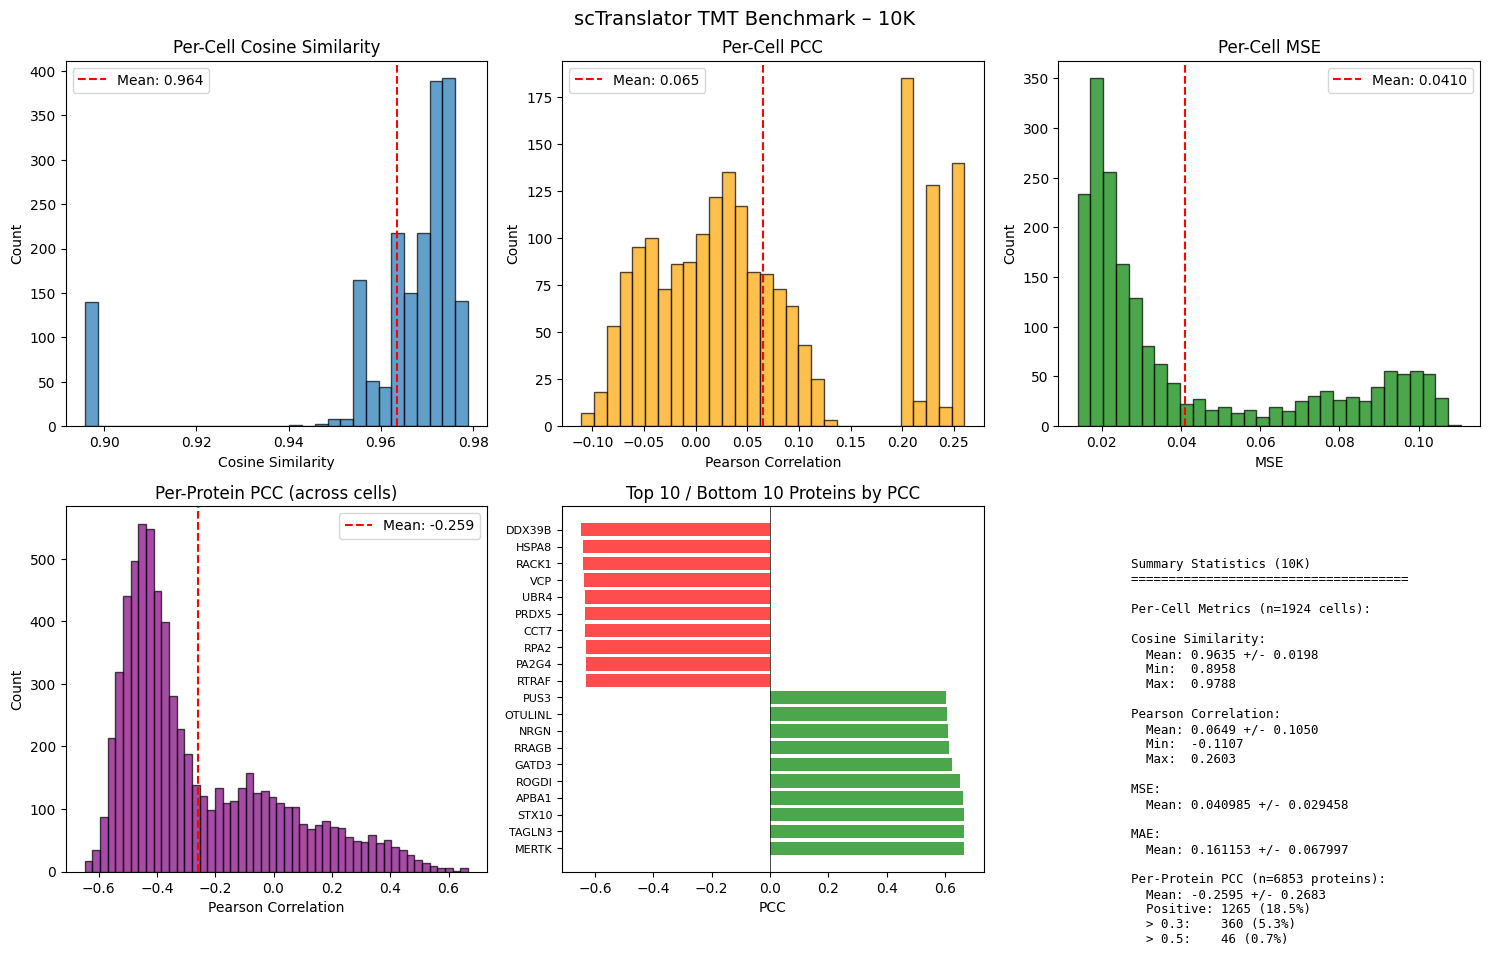

  Saved plot: benchmark_10K.png


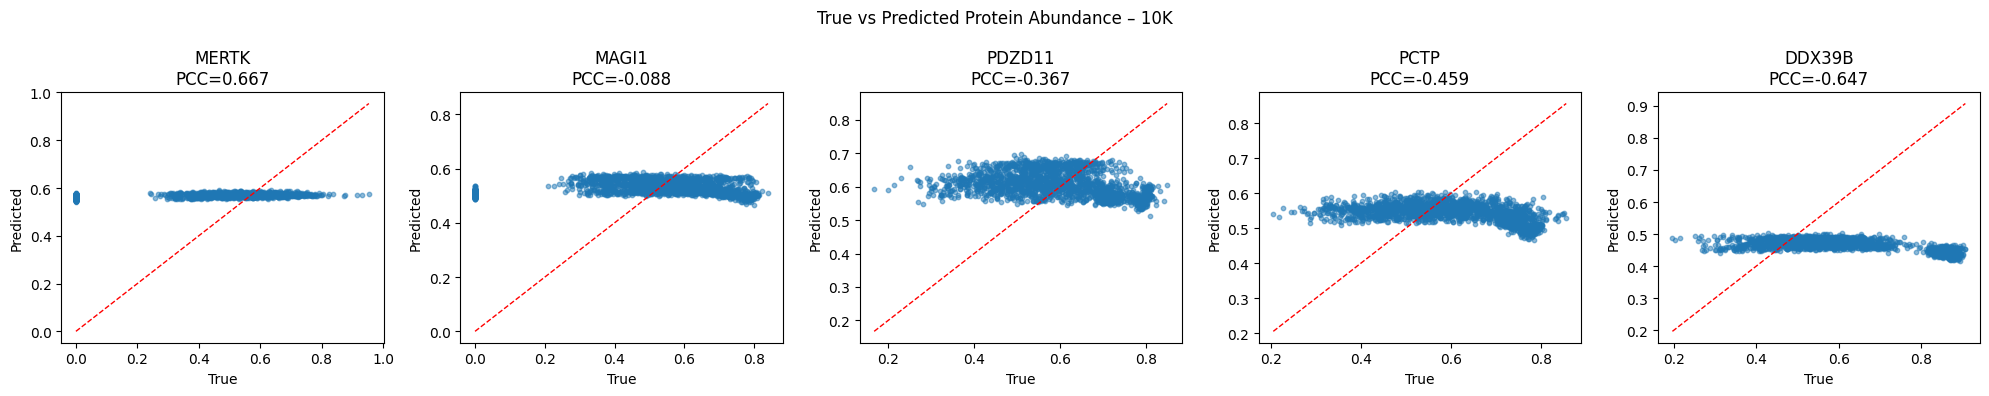

  Saved plot: scatter_10K.png

Benchmarking: 160K
Checkpoint: C:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator stuff\scTranslator_160K.pt

Loading model...
  Model loaded on cuda

Running inference...

Protein chunking: 6853 proteins -> 7 chunks of <=1000
  Chunk 1/7: proteins 0-1000 (1000 proteins)


  Chunk 1: 100%|██████████| 241/241 [01:16<00:00,  3.16it/s]


  Chunk 2/7: proteins 1000-2000 (1000 proteins)


  Chunk 2: 100%|██████████| 241/241 [01:04<00:00,  3.74it/s]


  Chunk 3/7: proteins 2000-3000 (1000 proteins)


  Chunk 3: 100%|██████████| 241/241 [02:06<00:00,  1.91it/s]


... (5 outputs left out)

  Chunk 6: 100%|██████████| 241/241 [08:10<00:00,  2.03s/it]


  Chunk 7/7: proteins 6000-6853 (853 proteins)


  Chunk 7: 100%|██████████| 241/241 [01:00<00:00,  3.96it/s]


  Saved predictions: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\tmt\benchmark_results_tmt\predictions_160K.npy

Computing metrics...

--- Results for 160K ---
Per-Cell Cosine: -0.5985 +/- 0.0160
Per-Cell PCC:    -0.0034 +/- 0.0184
Per-Cell MSE:    40987.474953 +/- 11670.478290
Per-Cell MAE:    189.204496 +/- 30.649754
Per-Protein PCC: 0.2147 +/- 0.4246

Generating visualizations...


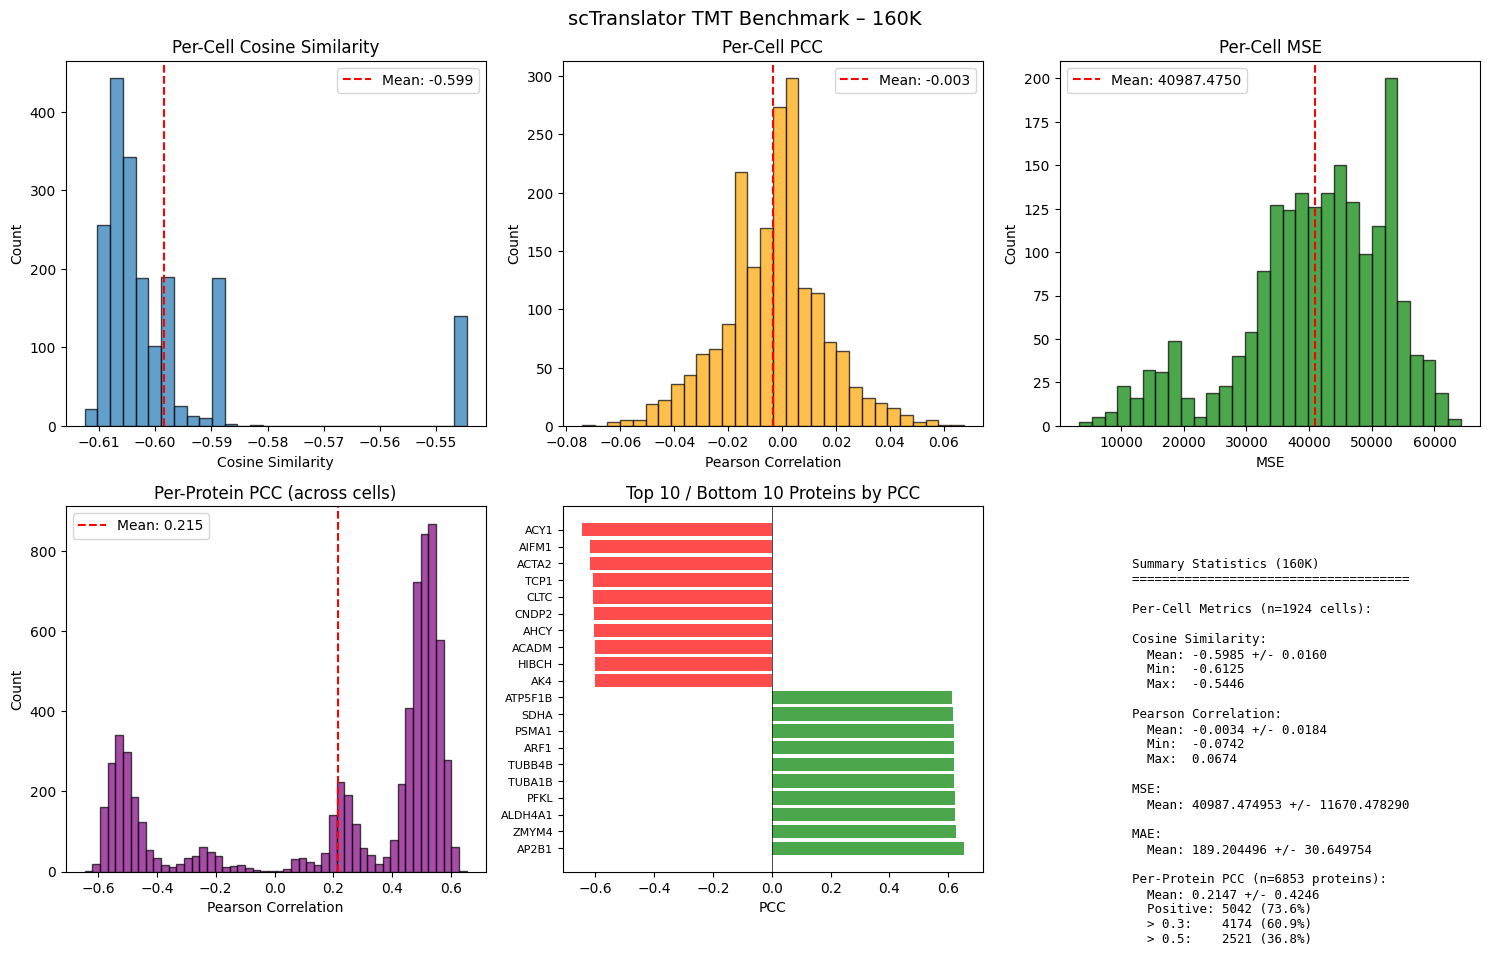

  Saved plot: benchmark_160K.png


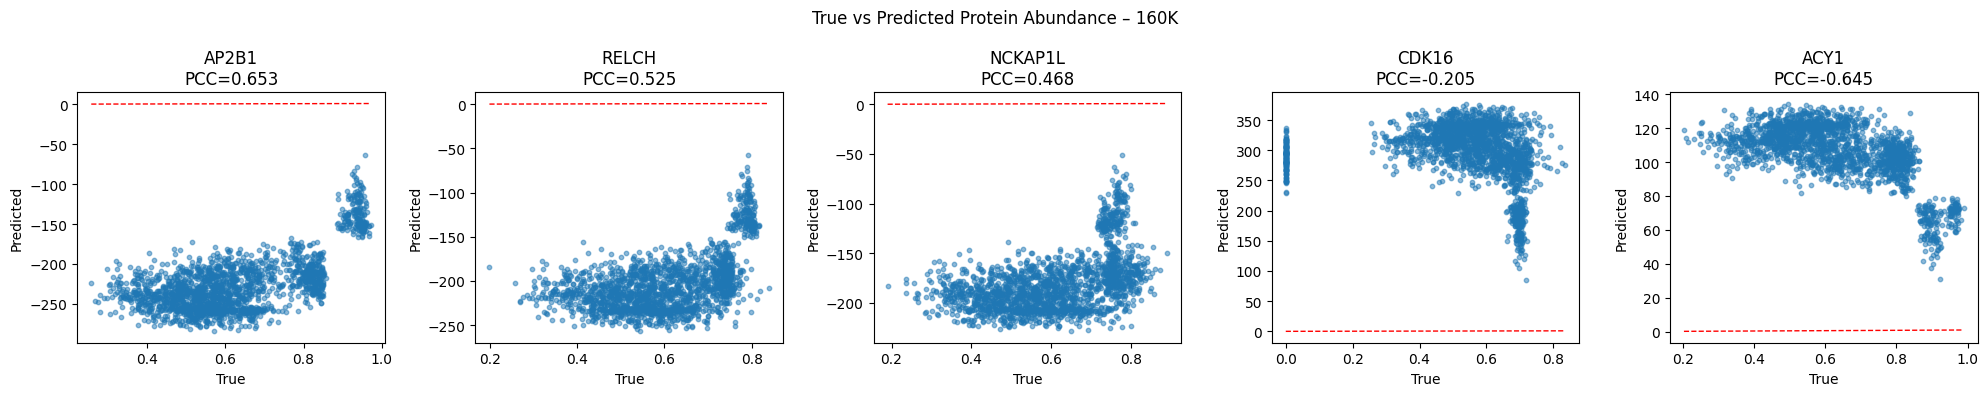

  Saved plot: scatter_160K.png


In [13]:
all_results = {}

for ckpt_name, ckpt_file in CONFIG['checkpoints'].items():
    if os.path.exists(ckpt_file):
        results = benchmark_checkpoint(ckpt_name, ckpt_file, data, CONFIG, device)
        all_results[ckpt_name] = results

        # Save individual results
        np.savez(
            os.path.join(CONFIG['output_dir'], f'results_{ckpt_name}.npz'),
            predictions=results['predictions'],
            cosine=results['metrics']['cosine'],
            pcc=results['metrics']['pcc'],
            mse=results['metrics']['mse'],
            mae=results['metrics']['mae'],
            protein_pccs=results['protein_pccs'],
        )

        # Clear GPU memory between checkpoints
        if device == 'cuda':
            torch.cuda.empty_cache()
    else:
        print(f"\nWarning: Checkpoint not found: {ckpt_file}")

### 10.4 Checkpoint Comparison Plot


Generating comparison plots...


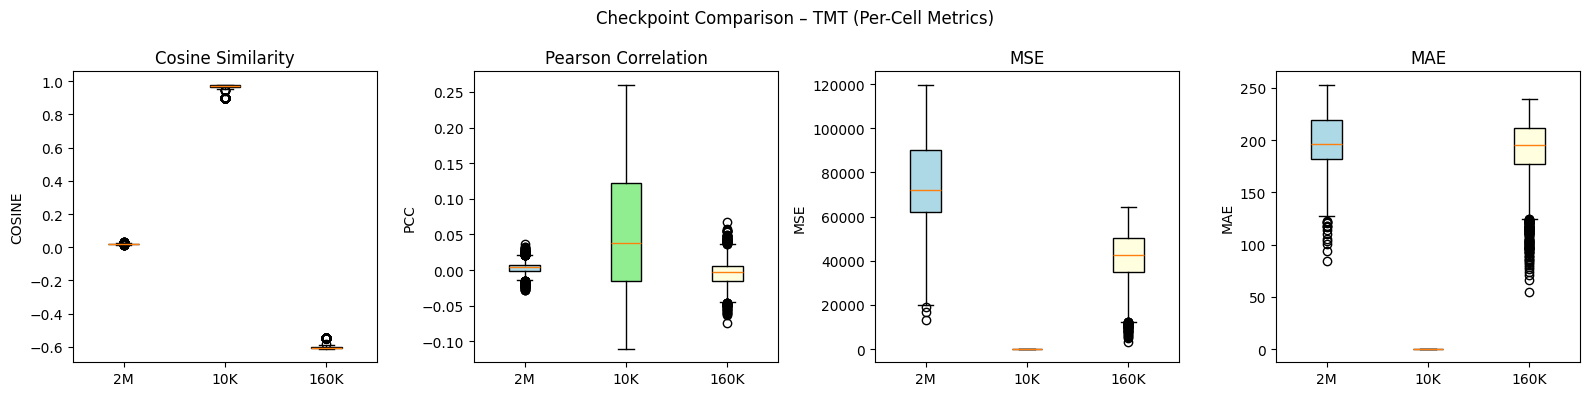

  Saved: checkpoint_comparison.png


In [14]:
if len(all_results) > 1:
    print("\n" + "=" * 60)
    print("Generating comparison plots...")
    print("=" * 60)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    metrics_to_plot = ['cosine', 'pcc', 'mse', 'mae']
    titles = ['Cosine Similarity', 'Pearson Correlation', 'MSE', 'MAE']

    for ax, metric, title in zip(axes, metrics_to_plot, titles):
        data_to_plot = [all_results[k]['metrics'][metric] for k in all_results]
        labels = list(all_results.keys())

        bp = ax.boxplot(data_to_plot, labels=labels, patch_artist=True)
        colors_bp = ['lightblue', 'lightgreen', 'lightyellow'][:len(labels)]
        for patch, color in zip(bp['boxes'], colors_bp):
            patch.set_facecolor(color)

        ax.set_title(title)
        ax.set_ylabel(metric.upper())

    plt.suptitle('Checkpoint Comparison – TMT (Per-Cell Metrics)', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(CONFIG['output_dir'], 'checkpoint_comparison.png'), dpi=150)
    plt.show()
    print(f"  Saved: checkpoint_comparison.png")
else:
    print("Only one (or zero) checkpoints ran – skipping comparison plot.")

### 10.5 Final Summary & Save

In [15]:
print("\n" + "=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

ms = data['mapping_stats']

summary_lines = []
for ckpt_name, results in all_results.items():
    m  = results['metrics']
    pp = results['protein_pccs']
    line = (f"{ckpt_name}: Cosine={m['cosine'].mean():.4f}, "
            f"PCC={m['pcc'].mean():.4f}, MSE={m['mse'].mean():.6f}, "
            f"Protein-PCC={pp.mean():.4f}")
    print(line)
    summary_lines.append(line)

with open(os.path.join(CONFIG['output_dir'], 'summary.txt'), 'w') as f:
    f.write("scTranslator Benchmark Summary – iTRAQ Dataset\n")
    f.write("=" * 60 + "\n\n")
    f.write(f"Raw dataset: {data['n_cells']} samples x "
            f"{ms['prot_total']} proteins, {ms['rna_total']} RNA genes\n\n")

    f.write(f"Step 1: NaN Handling (threshold: >{ms['nan_threshold']*100:.0f}% NaN -> drop, "
            f"else fill with 1e-8)\n")
    f.write("-" * 50 + "\n")
    f.write(f"  RNA genes dropped (>{ms['nan_threshold']*100:.0f}% NaN): {ms['rna_dropped_nan']} / {ms['rna_total']} "
            f"({100*ms['rna_dropped_nan']/ms['rna_total']:.1f}%)\n")
    f.write(f"  RNA genes filled  (<=50% NaN):  {ms['rna_filled_nan']} / {ms['rna_total']} "
            f"({100*ms['rna_filled_nan']/ms['rna_total']:.1f}%)\n")
    f.write(f"  Proteins dropped  (>{ms['nan_threshold']*100:.0f}% NaN): {ms['prot_dropped_nan']} / {ms['prot_total']} "
            f"({100*ms['prot_dropped_nan']/ms['prot_total']:.1f}%)\n")
    f.write(f"  Proteins filled   (<=50% NaN):  {ms['prot_filled_nan']} / {ms['prot_total']} "
            f"({100*ms['prot_filled_nan']/ms['prot_total']:.1f}%)\n")
    f.write(f"  RNA genes remaining:          {ms['rna_after_nan']}\n")
    f.write(f"  Proteins remaining:           {ms['prot_after_nan']}\n\n")

    f.write("Step 2: scTranslator Vocabulary Mapping\n")
    f.write("-" * 50 + "\n")
    f.write(f"  RNA genes mapped:             {ms['rna_mapped']} / {ms['rna_after_nan']} "
            f"({100*ms['rna_mapped']/ms['rna_after_nan']:.1f}%)\n")
    f.write(f"  RNA genes unmapped:           {ms['rna_unmapped']}\n")
    f.write(f"  Proteins mapped:              {ms['prot_mapped']} / {ms['prot_after_nan']} "
            f"({100*ms['prot_mapped']/ms['prot_after_nan']:.1f}%)\n")
    f.write(f"  Proteins unmapped:            {ms['prot_unmapped']}\n")
    f.write(f"  Unmapped protein names:       {ms['prot_unmapped_names']}\n\n")

    f.write("Total Attrition\n")
    f.write("-" * 50 + "\n")
    f.write(f"  RNA:  {ms['rna_total']} -> {data['n_rna_genes']}  "
            f"(dropped {ms['rna_dropped_nan']} NaN + {ms['rna_unmapped']} unmapped, "
            f"{ms['rna_filled_nan']} cols NaN-filled)\n")
    f.write(f"  Prot: {ms['prot_total']} -> {data['n_proteins']}  "
            f"(dropped {ms['prot_dropped_nan']} NaN + {ms['prot_unmapped']} unmapped, "
            f"{ms['prot_filled_nan']} cols NaN-filled)\n\n")

    f.write(f"Final input: {data['n_cells']} samples x "
            f"{data['n_proteins']} proteins, {data['n_rna_genes']} RNA genes\n\n")
    f.write("Benchmark Results\n")
    f.write("-" * 50 + "\n")
    for line in summary_lines:
        f.write(line + "\n")

print(f"\nResults saved to: {CONFIG['output_dir']}")
print("Done!")


FINAL SUMMARY
2M: Cosine=0.0204, PCC=0.0035, MSE=75772.253742, Protein-PCC=0.0562
10K: Cosine=0.9635, PCC=0.0649, MSE=0.040985, Protein-PCC=-0.2595
160K: Cosine=-0.5985, PCC=-0.0034, MSE=40987.474953, Protein-PCC=0.2147

Results saved to: c:\Users\avsd8\OneDrive\Desktop\thesis\scTranslator furthger bencharmking\tmt\benchmark_results_tmt
Done!
